# K-means on the station-window features

A worked example of how a clustering method connects to the data pipeline. Every method follows the same four steps:

1. **Read** the feature table **straight from S3**: the Parquet files Athena writes to `s3://<bucket>/curated/features/` (`sql/06_features.sql`). This needs AWS access (`export AWS_PROFILE=data-mining` for teammates; see `docs/TEAM_SETUP.md`).
2. **Split** the identifying columns from the 17 features. The features become the matrix `X` (244 rows x 17 columns, already z-scored).
3. **Fit** the method on `X`.
4. **Save** one label per row in the shared format, `results/labels/<method>.parquet`, so the evaluation can compare every method the same way.

Settings follow the Methodology: k-means++ starts, 50 restarts, seed 42, k from 2 to 10.

In [1]:
from pathlib import Path
import awswrangler as wr
import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REGION = "ap-south-1"
session = boto3.Session(region_name=REGION)
ACCOUNT_ID = session.client("sts").get_caller_identity()["Account"]
BUCKET = f"dubai-metro-profiling-{ACCOUNT_ID}"
FEATURES_S3 = f"s3://{BUCKET}/curated/features/"            # z-scored, built by Athena
UNSCALED_S3 = f"s3://{BUCKET}/curated/features_unscaled/"   # same rows before scaling
HAND_LABELS = ROOT / "results" / "hand_labels.csv"
LABELS_DIR = ROOT / "results" / "labels"
METRICS_DIR = ROOT / "results" / "metrics"
FIGURES = ROOT / "figures"
for folder in (LABELS_DIR, METRICS_DIR, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
RESTARTS = 50
K_RANGE = range(2, 11)

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.edgecolor": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 130})
pd.set_option("display.width", 200, "display.max_columns", 30)

## 1. Read the feature table from S3 and build X

In [2]:
df = wr.s3.read_parquet(FEATURES_S3, boto3_session=session).sort_values(["location_id", "win"]).reset_index(drop=True)
print("read", len(df), "rows from", FEATURES_S3.replace(ACCOUNT_ID, "<account>"))
ID_COLUMNS = ["win", "location_id", "station", "timed_taps", "check_ins", "check_outs"]
FEATURE_COLUMNS = [c for c in df.columns if c not in ID_COLUMNS]
X = df[FEATURE_COLUMNS].to_numpy()
print("X shape:", X.shape)
print("features:", FEATURE_COLUMNS)
assert X.shape == (244, 17) and not np.isnan(X).any()

read 244 rows from s3://dubai-metro-profiling-<account>/curated/features/
X shape: (244, 17)
features: ['check_in_share_00_07', 'check_in_share_07_10', 'check_in_share_10_16', 'check_in_share_16_20', 'check_in_share_20_24', 'check_out_share_00_07', 'check_out_share_07_10', 'check_out_share_10_16', 'check_out_share_16_20', 'check_out_share_20_24', 'net_flow_00_07', 'net_flow_07_10', 'net_flow_10_16', 'net_flow_16_20', 'net_flow_20_24', 'weekend_share', 'volume_share']


## 2. Choose k
Fit K-means for every k from 2 to 10 and record the four internal metrics. SSE always falls as k grows, so look for the elbow; silhouette is better when higher, Davies-Bouldin when lower, Calinski-Harabasz when higher.

In [3]:
rows = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, init="k-means++", n_init=RESTARTS, random_state=SEED).fit(X)
    rows.append({"k": k, "sse": model.inertia_,
                 "silhouette": silhouette_score(X, model.labels_),
                 "davies_bouldin": davies_bouldin_score(X, model.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, model.labels_),
                 "smallest_cluster": int(np.bincount(model.labels_).min())})
sweep = pd.DataFrame(rows).round(4)
sweep.to_csv(METRICS_DIR / "kmeans_k_sweep.csv", index=False)
sweep

,k,sse,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
0,2,2618.6913,0.3302,1.2234,141.3274,107
1,3,2110.0391,0.2725,1.3549,116.3838,51
2,4,1749.3723,0.2858,1.3314,109.6909,44
3,5,1560.9359,0.2625,1.4042,99.0285,41
4,6,1426.0136,0.2696,1.3129,90.8593,6
5,7,1304.0710,0.2702,1.2464,86.1419,6
6,8,1216.4788,0.2404,1.3069,81.2461,6
7,9,1145.0422,0.2326,1.3348,77.0381,6
8,10,1071.4343,0.2488,1.2742,74.6576,6


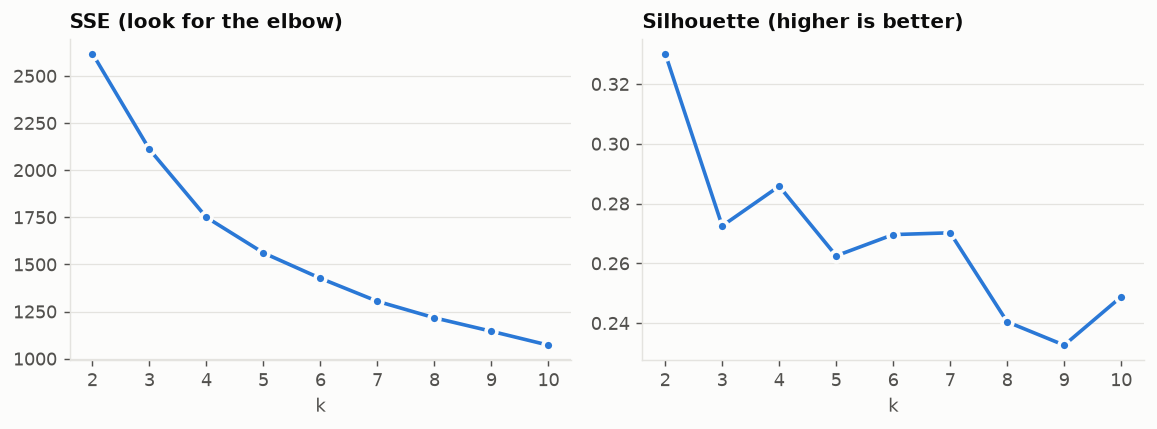

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, column, title in ((axes[0], "sse", "SSE (look for the elbow)"),
                          (axes[1], "silhouette", "Silhouette (higher is better)")):
    ax.plot(sweep.k, sweep[column], color=SERIES[0], lw=2, marker="o", ms=6, mec=SURFACE, mew=2)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("k")
    ax.set_xticks(list(K_RANGE))
    ax.grid(axis="y", color=GRID, lw=0.7)
fig.tight_layout()
fig.savefig(FIGURES / "kmeans_k_selection.png", dpi=200)

## 3. Fit the chosen k
`K` is the team's choice after reading the sweep. It starts at the k with the best silhouette; change it here if the elbow or the cluster profiles argue for another value.

In [5]:
K = int(sweep.loc[sweep.silhouette.idxmax(), "k"])
model = KMeans(n_clusters=K, init="k-means++", n_init=RESTARTS, random_state=SEED).fit(X)
print(f"K = {K}")
print(sweep[sweep.k == K].to_string(index=False))
print("rows per cluster:", np.bincount(model.labels_).tolist())

K = 2
 k       sse  silhouette  davies_bouldin  calinski_harabasz  smallest_cluster
 2 2618.6913      0.3302          1.2234           141.3274               107
rows per cluster: [107, 137]


## 4. Save labels in the shared format
Every method writes the same columns, so one evaluation script reads them all. `alpha` is only used by ST-GRSC; DBSCAN will use -1 for noise.

In [6]:
labels = df[["win", "location_id", "station"]].copy()
labels["method"] = "kmeans"
labels["k"] = K
labels["alpha"] = np.nan
labels["cluster"] = model.labels_
labels.to_parquet(LABELS_DIR / "kmeans.parquet", index=False)
labels.head()

,win,location_id,station,method,k,alpha,cluster
0,W17/18,128,centrepoint,kmeans,2,NaN,1
1,W18/19,128,centrepoint,kmeans,2,NaN,1
2,W19/20,128,centrepoint,kmeans,2,NaN,1
3,W21/22,128,centrepoint,kmeans,2,NaN,1
4,W24/25,128,centrepoint,kmeans,2,NaN,1


## 5. What each cluster looks like
Average unscaled features per cluster. These profiles are what you name the clusters from (for example: morning arrivals and evening departures suggest a business area).

In [7]:
unscaled = wr.s3.read_parquet(UNSCALED_S3, boto3_session=session)
profile = unscaled.merge(labels[["win", "location_id", "cluster"]], on=["win", "location_id"])
summary = profile.groupby("cluster")[FEATURE_COLUMNS].mean()
summary.insert(0, "rows", profile.groupby("cluster").size())
summary.round(3).to_csv(METRICS_DIR / "kmeans_cluster_profiles.csv")
summary.round(3).T

cluster,0,1
rows,107.000,137.000
check_in_share_00_07,0.023,0.059
check_in_share_07_10,0.089,0.216
check_in_share_10_16,0.252,0.279
check_in_share_16_20,0.458,0.289
check_in_share_20_24,0.177,0.158
check_out_share_00_07,0.052,0.041
check_out_share_07_10,0.306,0.121
check_out_share_10_16,0.282,0.238
check_out_share_16_20,0.234,0.356


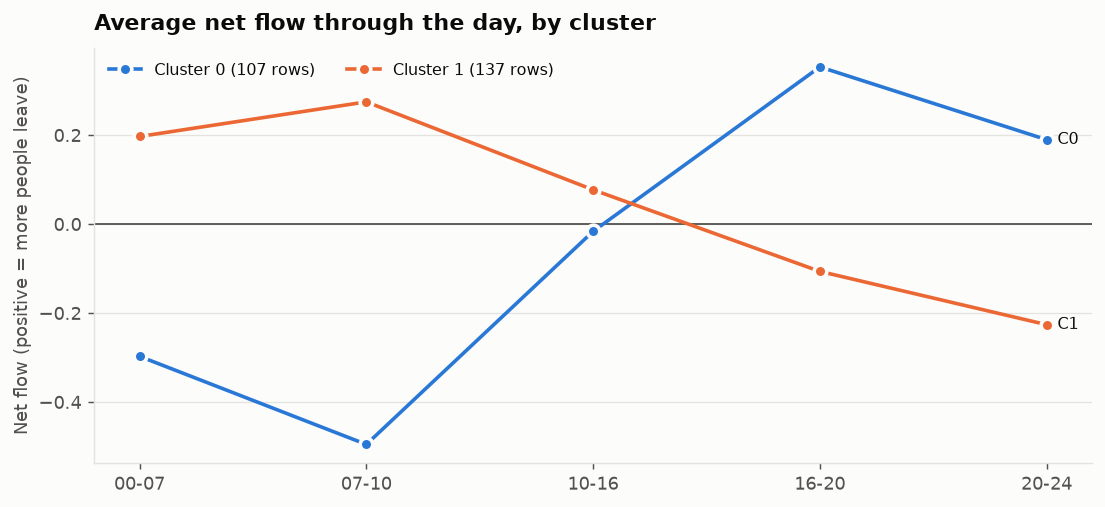

In [8]:
bands = ["00_07", "07_10", "10_16", "16_20", "20_24"]
band_labels = ["00-07", "07-10", "10-16", "16-20", "20-24"]
fig, ax = plt.subplots(figsize=(8.6, 4))
ax.axhline(0, color=MUTED, lw=1)
for cluster in summary.index:
    values = [summary.loc[cluster, f"net_flow_{b}"] for b in bands]
    ax.plot(band_labels, values, color=SERIES[cluster % len(SERIES)], lw=2, marker="o", ms=7, mec=SURFACE, mew=2,
            label=f"Cluster {cluster} ({int(summary.loc[cluster, 'rows'])} rows)")
    ax.annotate(f"C{cluster}", (len(bands) - 1, values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.set_ylabel("Net flow (positive = more people leave)")
ax.grid(axis="y", color=GRID, lw=0.7)
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
ax.set_title("Average net flow through the day, by cluster", loc="left", fontsize=12, fontweight="bold", pad=10)
fig.tight_layout()
fig.savefig(FIGURES / "kmeans_cluster_net_flow.png", dpi=200)

## 6. Check against the 12 validation labels
Each labelled station has up to five rows (one per window). For each station: the cluster it falls in most often, and in how many of its windows.

In [9]:
hand = pd.read_csv(HAND_LABELS)
check = labels.merge(hand[["location_id", "expected_type", "seen_in_charts"]], on="location_id")
per_station = (check.groupby(["station", "expected_type", "seen_in_charts"])["cluster"]
               .agg(main_cluster=lambda s: s.mode().iloc[0],
                    windows_in_main=lambda s: int((s == s.mode().iloc[0]).sum()),
                    windows=lambda s: len(s))
               .reset_index().sort_values(["main_cluster", "expected_type"]))
per_station.to_csv(METRICS_DIR / "kmeans_vs_hand_labels.csv", index=False)
per_station

,station,expected_type,seen_in_charts,main_cluster,windows_in_main,windows
5,Dubai Healthcare City,Business,no,0,5,5
10,Oud Metha,Education,no,0,5,5
4,DMCC,Mixed,no,0,5,5
6,EXPO,Shopping and leisure,no,0,2,2
0,Airport Terminal 3,Airport,yes,1,5,5
7,Financial Centre,Business,yes,1,4,5
2,Al Rigga,Mixed,no,1,5,5
11,Stadium,Residential,no,1,5,5
8,Ibn Battuta,Shopping and leisure,no,1,3,5
9,Mall of the Emirates,Shopping and leisure,yes,1,3,5


In [10]:
pd.crosstab(per_station.expected_type, per_station.main_cluster)

main_cluster,0,1
expected_type,,
Airport,0,1
Business,1,1
Education,1,0
Mixed,1,1
Residential,0,1
Shopping and leisure,1,2
Transfer and hub,0,2


## How the other methods plug in

| Method | Owner | Change from this notebook |
|---|---|---|
| Hierarchical (Ward) | Chaitanya | `AgglomerativeClustering(n_clusters=K, linkage="ward")` |
| DBSCAN | Aryan | `DBSCAN(eps=..., min_samples=...)`; no k; noise is -1 |
| Spectral (alpha = 1) | Ashfaque | similarity from `X` only |
| ST-GRSC | Ashfaque | similarity from `X` blended with the station graph (`edges.csv`) |

Each one reads the same `X` and writes `results/labels/<method>.parquet` with the same columns.